# Opdracht 1: Voorspel herseninfarct

**Teamnaam: 6** 

Aroetin Avanesi

Moreo Rahiembaks

Kaylim Taai

## Inhoudsopgave
1. Inleiding
2. Exploratieve Data Analyse
3. Evaluatie
4. Modellen
5. Conclusie en advies
6. Referenties

## 1. Inleiding

MedPredict is een medisch technologiebedrijf dat zorginstellingen en ziekenhuizen helpt om gezondheidsrisico's vroeg te herkennen. Het bedrijf heeft geanonimiseerde patiëntgegevens met demografische kenmerken, leefstijl en medische informatie.

Ongeveer 90% van de herseninfarcten hangt samen met risicofactoren die vooraf te meten en te beïnvloeden zijn, zoals hoge bloeddruk, roken en diabetes (O'Donnell et al., 2016). Als je patiënten met een verhoogd risico op tijd kunt herkennen, zijn artsen in staat om eerder in te grijpen met preventieve maatregelen.

Ons team bestaande uit junior data scientists is gevraagd om een machine learning model te bouwen dat dit risico voorspelt. MedPredict vergelijkt de oplossingen van verschillende teams via een interne Kaggle competitie.

### 1.1 Probleemstelling

MedPredict wil een model dat:
* op basis van patiëntgegevens voorspelt of iemand een herseninfarct kan krijgen
* zo min mogelijk patiënten met een verhoogd risico mist, maar ook zo min mogelijk valse alarmen geeft
* betrouwbaar en duidelijk genoeg is om artsen te ondersteunen

Omdat we hier te maken hebben met een medische toepassing, kunnen fouten leiden tot echte gevolgen. Een gemiste patiënt zou bijvoorbeeld geen preventie krijgen, terwijl een vals alarm iemand onnodige zorgen en lasten kan geven. Daarom kijken we niet alleen naar de score, maar ook naar de keuzes die we maken en beoordelen we hoe betrouwbaar het model is.

## 2. Exploratieve Data Analyse

### 2.1 Data inladen

In [1]:
from pathlib import Path

import pandas as pd


class StrokeData:
    """Laadt de datasets van de Kaggle competitie Predicting stroke."""

    def __init__(self, data_dir="data"):
        # Map waarin de csv bestanden staan
        self.data_dir = Path(data_dir)
        self.train = None
        self.test = None
        self.submission = None

    def load(self):
        """Leest alle drie de csv bestanden in als DataFrames."""
        self.train = pd.read_csv(self.data_dir / "train.csv")
        self.test = pd.read_csv(self.data_dir / "test.csv")
        self.submission = pd.read_csv(
            self.data_dir / "sample_submission.csv"
        )
        return self

    def check_shapes(self):
        """Toont het aantal rijen en kolommen van iedere dataset."""
        print(f"train:      {self.train.shape}")
        print(f"test:       {self.test.shape}")
        print(f"submission: {self.submission.shape}")


data = StrokeData().load()
data.check_shapes()
data.train.head()

train:      (33550, 22)
test:       (8388, 21)
submission: (8388, 2)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


### 2.2 Uitleg kolommen

De dataset bevat 33.550 patiënten en 22 kolommen. De originele categorische kolommen (zoals geslacht en soort werk) zijn al door Kaggle omgezet naar **dummy-kolommen**: voor iedere categorie is er een aparte kolom met `True` of `False`. Per patiënt staat binnen een groep precies één kolom op `True`, behalve bij roken (zie hieronder).

| Kolom | Soort | Uitleg |
|---|---|---|
| `id` | identificatie | Uniek nummer per patiënt. Bevat geen medische informatie en is alleen nodig om voorspellingen aan de juiste patiënt te koppelen bij de Kaggle-inlevering. |
| `age` | numeriek | Leeftijd in jaren, van 0,08 (een baby van ongeveer 1 maand) tot 82 jaar. Bij kinderen onder de 2 jaar is de leeftijd een kommagetal. |
| `hypertension` | binair (0/1) | 1 = de patiënt heeft hoge bloeddruk (hypertensie), 0 = niet. |
| `heart_disease` | binair (0/1) | 1 = de patiënt heeft een hartziekte, 0 = niet. |
| `avg_glucose_level` | numeriek | Gemiddeld suikergehalte (glucose) in het bloed in mg/dL, van 55 tot 282. Een hoge waarde kan wijzen op diabetes. |
| `bmi` | numeriek | Body Mass Index: gewicht (kg) gedeeld door lengte in het kwadraat (m²), van 10,1 tot 97,6. Tussen 18,5 en 25 geldt als gezond, boven 30 als obesitas. |
| `gender_Female`, `gender_Male`, `gender_Other` | dummy (True/False) | Geslacht van de patiënt: vrouw, man of anders. `gender_Other` komt maar 6 keer voor. |
| `ever_married_No`, `ever_married_Yes` | dummy (True/False) | Of de patiënt ooit getrouwd is geweest. |
| `work_type_Govt_job`, `work_type_Never_worked`, `work_type_Private`, `work_type_Self-employed`, `work_type_children` | dummy (True/False) | Soort werk: bij de overheid, nooit gewerkt, in de private sector, zelfstandige, of kind (werkt nog niet). |
| `Residence_type_Rural`, `Residence_type_Urban` | dummy (True/False) | Woonomgeving: platteland (rural) of stad (urban). |
| `smoking_status_formerly smoked`, `smoking_status_never smoked`, `smoking_status_smokes` | dummy (True/False) | Rookgedrag: vroeger gerookt, nooit gerookt of rookt. Als alle drie de kolommen `False` zijn, is de rookstatus onbekend. Dat geldt voor 10.320 patiënten (31%). |
| `stroke` | binair (0/1) | **Doelvariabele (y).** 1 = de patiënt heeft een herseninfarct gehad, 0 = niet. Deze kolom gaan we voorspellen. |

`stroke` is de afhankelijke variabele. Alle andere kolommen behalve `id` zijn onafhankelijke variabelen (features) die we gebruiken om `stroke` te voorspellen.

In [2]:
def describe_columns(df):
    """Datatype, aantal unieke waarden, bereik en voorbeelden per kolom."""
    return pd.DataFrame({
        "datatype": df.dtypes.astype(str),
        "uniek": df.nunique(),
        "min": df.min(),
        "max": df.max(),
        "voorbeelden": [df[col].unique()[:5] for col in df.columns],
    })


describe_columns(data.train)

,datatype,uniek,min,max,voorbeelden
id,int64,33550,1,72943,"[52709, 72295, 26451, 65210, 69299]"
age,float64,104,0.08,82.0,"[30.0, 75.0, 15.0, 47.0, 49.0]"
hypertension,int64,2,0,1,"[0, 1]"
heart_disease,int64,2,0,1,"[0, 1]"
avg_glucose_level,float64,11241,55.01,281.59,"[63.6, 215.17, 135.22, 64.89, 222.34]"
bmi,float64,542,10.1,97.6,"[33.3, 48.0, 19.0, 28.2, 28.8]"
gender_Female,bool,2,False,True,"[False, True]"
gender_Male,bool,2,False,True,"[True, False]"
gender_Other,bool,2,False,True,"[False, True]"
ever_married_No,bool,2,False,True,"[True, False]"


In [3]:
def count_true_per_row(df, columns):
    """Telt per rij hoeveel van de opgegeven dummy-kolommen True zijn."""
    # True telt als 1, False als 0
    return df[columns].sum(axis=1).value_counts()


smoking_cols = ["smoking_status_formerly smoked",
                "smoking_status_never smoked",
                "smoking_status_smokes"]
count_true_per_row(data.train, smoking_cols)

1    23230
0    10320
Name: count, dtype: int64

### 2.3 Datatypes en basisstatistieken

In [4]:
NUMERIC_COLS = ["age", "avg_glucose_level", "bmi"]
BINARY_COLS = ["hypertension", "heart_disease"]
TARGET = "stroke"


def show_overview(df):
    """Toont het formaat, ontbrekende waarden en dubbele rijen."""
    print(f"Aantal rijen: {df.shape[0]}, aantal kolommen: {df.shape[1]}")
    print(f"Ontbrekende waarden in totaal: {df.isna().sum().sum()}")
    # id laten we weg, anders is iedere rij uniek
    print(f"Dubbele rijen: {df.drop(columns='id').duplicated().sum()}")
    print("\nAantal kolommen per datatype:")
    print(df.dtypes.value_counts())


show_overview(data.train)
data.train.dtypes

Aantal rijen: 33550, aantal kolommen: 22
Ontbrekende waarden in totaal: 0
Dubbele rijen: 0

Aantal kolommen per datatype:
bool       15
int64       4
float64     3
Name: count, dtype: int64


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

In [5]:
# Gemiddelde, spreiding, minimum, kwartielen en maximum
data.train[NUMERIC_COLS].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


In [6]:
def percentage_true(df, columns):
    """Aantal en percentage patiënten met waarde 1/True per kolom."""
    return pd.DataFrame({
        "aantal": df[columns].sum(),
        "percentage": (df[columns].mean() * 100).round(2),
    })


dummy_cols = data.train.select_dtypes(include="bool").columns.tolist()
percentage_true(data.train, BINARY_COLS + dummy_cols + [TARGET])

,aantal,percentage
hypertension,2957,8.81
heart_disease,1444,4.30
gender_Female,20032,59.71
gender_Male,13512,40.27
gender_Other,6,0.02
ever_married_No,12124,36.14
ever_married_Yes,21426,63.86
work_type_Govt_job,4156,12.39
work_type_Never_worked,141,0.42
work_type_Private,19279,57.46


**Datatypes.** De dataset heeft 33.550 rijen en 22 kolommen. Daarvan zijn er 15 dummy-kolommen (`bool`), 4 gehele getallen (`int64`: `id`, `hypertension`, `heart_disease` en `stroke`) en 3 kommagetallen (`float64`: `age`, `avg_glucose_level` en `bmi`). Er ontbreken geen waarden en er zijn geen dubbele rijen.

**Numerieke kolommen.**
* `age`: Het gemiddelde (41,8) en de mediaan (43) liggen dicht bij elkaar, dus de verdeling is ongeveer symmetrisch.
* `avg_glucose_level`: het gemiddelde is 103,6, maar de mediaan is 91,3. Het gemiddelde ligt hoger doordat een deel van de patiënten een veel hogere waarde heeft (maximum 281,6). De verdeling is dus scheef naar rechts.
* `bmi`: het gemiddelde is 28,6 en de waarden lopen van 10,1 tot 97,6. Een BMI van 97,6 is extreem hoog. Of dit een fout of een echte uitschieter is, bekijken we bij de outliers in 2.5.
* De schalen verschillen sterk (`age` gaat tot 82, `avg_glucose_level` tot 282). Daarom moeten we de kolommen later nog standaardiseren (2.8).

**Binaire en dummy-kolommen.**
* Maar 1,54% van de patiënten heeft een stroke gehad (517 van de 33.550). De data is dus sterk imbalanced.
* 8,81% heeft hypertension (hoge bloeddruk) en 4,30% heeft een hartziekte.
* `gender_Other` komt maar 6 keer voor (0,02%) en `work_type_Never_worked` 141 keer (0,42%). Dat zijn hele kleine groepen.
* Stad en platteland zijn bijna precies even groot (16.774 tegen 16.776, beide 50,00%).

### 2.4 Voldoet de data aan de eisen van Scikit-Learn?

In [7]:
import numpy as np


def check_sklearn_ready(X, y):
    """Controleert of X en y voldoen aan de eisen van scikit-learn."""
    text_cols = X.select_dtypes(include="object").columns.tolist()
    print("Geen tekstkolommen:      ", len(text_cols) == 0)
    print("Geen ontbrekende waarden:", X.isna().sum().sum() == 0)
    print("Geen oneindige waarden:  ", not np.isinf(X.astype(float)).any().any())
    print("X is een tabel (2D):     ", X.ndim == 2)
    print("y is één kolom (1D):     ", y.ndim == 1)
    print("X en y even lang:        ", len(X) == len(y))


# X = de features, y = wat we willen voorspellen
X = data.train.drop(columns=["id", TARGET])
y = data.train[TARGET]
check_sklearn_ready(X, y)

Geen tekstkolommen:       True
Geen ontbrekende waarden: True
Geen oneindige waarden:   True
X is een tabel (2D):      True
y is één kolom (1D):      True
X en y even lang:         True


Om een model te kunnen trainen met scikit-learn moet de data aan een paar minimale eisen voldoen:

1. **Alles is numeriek.** Een model rekent met getallen, niet met tekst zoals "Male" of "Urban".
2. **Geen ontbrekende waarden.** De meeste modellen geven een foutmelding bij lege cellen (`NaN`).
3. **Geen oneindige waarden** (`inf`).
4. **De juiste vorm.** X (de features) is een tabel met rijen en kolommen, y (de doelvariabele) is één kolom, en ze hebben evenveel rijen.

Onze data voldoet al aan deze eisen. Kaggle heeft de tekstkolommen al omgezet naar dummy-kolommen (`True`/`False`), en scikit-learn rekent `True` als 1 en `False` als 0. Er zijn geen ontbrekende of oneindige waarden.

Wel halen we `id` uit X. Het is een volgnummer zonder medische betekenis, en als we het laten staan kan een model er toevallige patronen in vinden.

### 2.5 Relaties tussen de variabelen en stroke

stroke
0    98.46
1     1.54
Name: proportion, dtype: float64


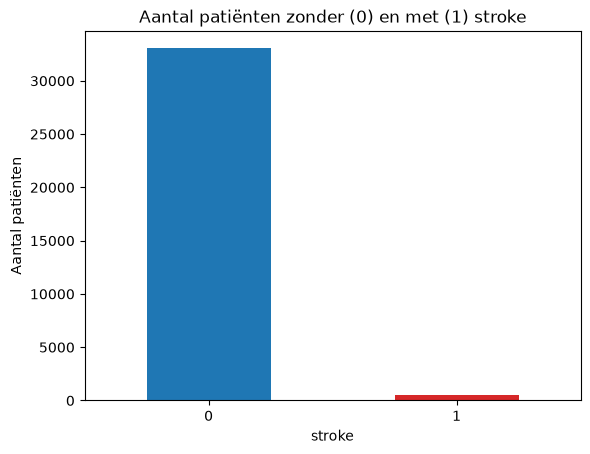

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = data.train[TARGET].value_counts()
print((data.train[TARGET].value_counts(normalize=True) * 100).round(2))

counts.plot(kind="bar", color=["tab:blue", "tab:red"])
plt.title("Aantal patiënten zonder (0) en met (1) stroke")
plt.xlabel("stroke")
plt.ylabel("Aantal patiënten")
plt.xticks(rotation=0)
plt.show()

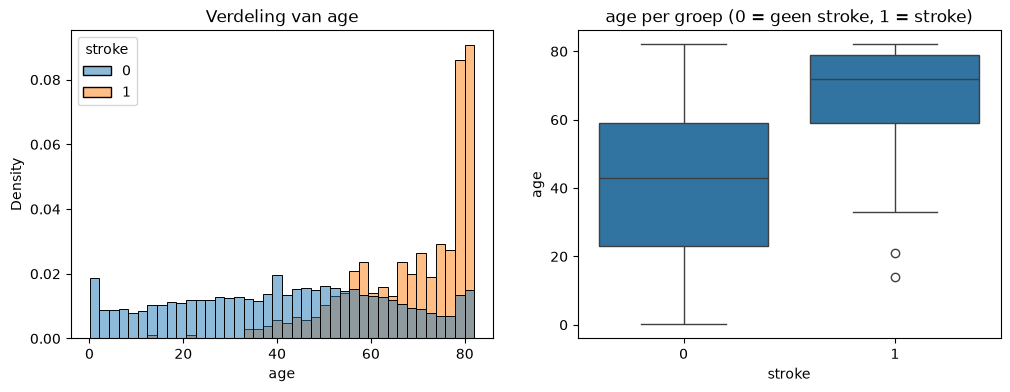

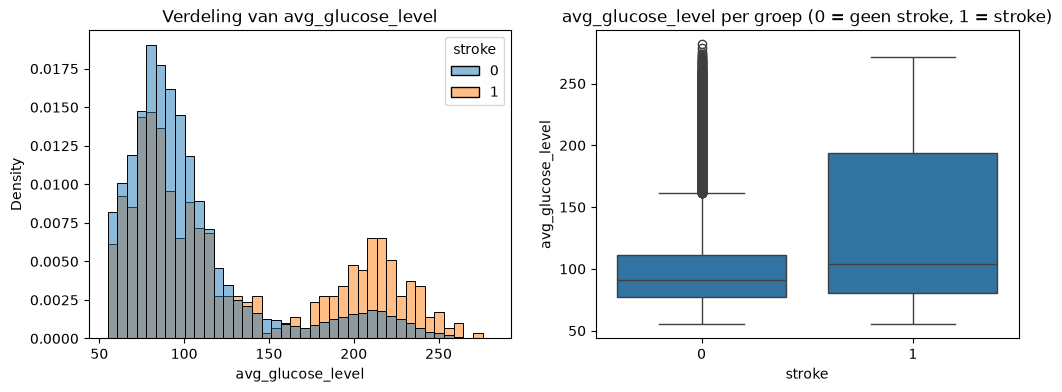

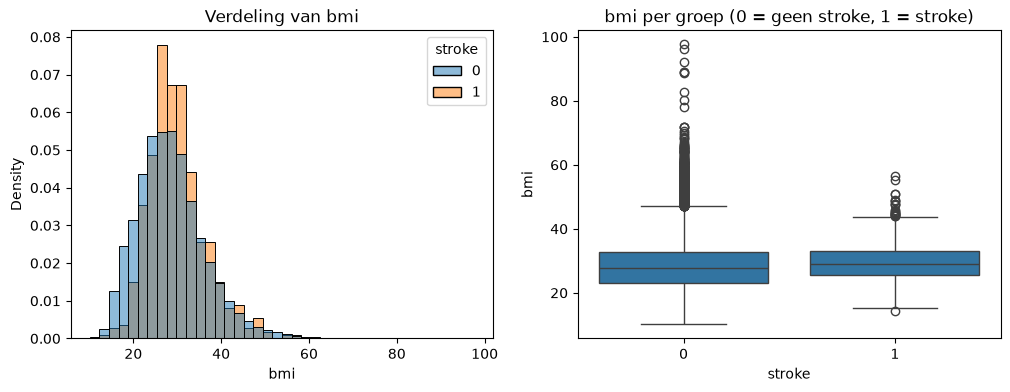

,age,avg_glucose_level,bmi
stroke,,,
0,43.0,91.22,27.7
1,72.0,104.12,29.0


In [9]:
def plot_numeric_by_target(df, columns, target):
    """Histogram en boxplot per numerieke kolom, gesplitst op stroke."""
    for col in columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        # common_norm=False: beide groepen even hoog, ook de kleine groep
        sns.histplot(data=df, x=col, hue=target, stat="density",
                     common_norm=False, bins=40, ax=axes[0])
        axes[0].set_title(f"Verdeling van {col}")
        sns.boxplot(data=df, x=target, y=col, ax=axes[1])
        axes[1].set_title(f"{col} per groep (0 = geen stroke, 1 = stroke)")
        plt.show()


plot_numeric_by_target(data.train, NUMERIC_COLS, TARGET)
data.train.groupby(TARGET)[NUMERIC_COLS].median()

In [10]:
def count_outliers(df, columns):
    """Telt per kolom de outliers volgens de IQR-regel."""
    rows = []
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        # Buiten deze grenzen is een waarde een outlier
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        rows.append({"kolom": col, "ondergrens": lower,
                     "bovengrens": upper, "aantal outliers": len(outliers),
                     "% stroke bij outliers": outliers[TARGET].mean() * 100})
    return pd.DataFrame(rows).round(2)


count_outliers(data.train, NUMERIC_COLS)

,kolom,ondergrens,bovengrens,aantal outliers,% stroke bij outliers
0,age,-28.50,111.50,0,NaN
1,avg_glucose_level,26.49,162.40,3641,4.48
2,bmi,9.05,47.05,769,1.30


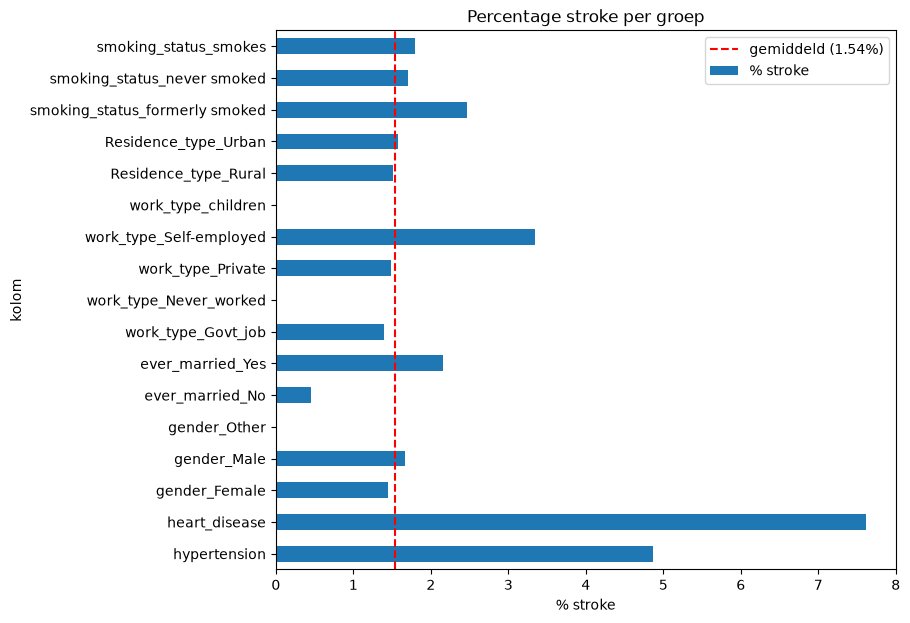

,aantal patiënten,% stroke
kolom,,
hypertension,2957,4.87
heart_disease,1444,7.62
gender_Female,20032,1.45
gender_Male,13512,1.67
gender_Other,6,0.00
ever_married_No,12124,0.45
ever_married_Yes,21426,2.16
work_type_Govt_job,4156,1.40
work_type_Never_worked,141,0.00


In [11]:
def stroke_percentage(df, columns, target):
    """Percentage stroke bij patiënten waarbij de kolom 1/True is."""
    rows = []
    for col in columns:
        group = df[df[col] == 1]
        rows.append({"kolom": col, "aantal patiënten": len(group),
                     "% stroke": group[target].mean() * 100})
    return pd.DataFrame(rows).set_index("kolom").round(2)


dummy_cols = data.train.select_dtypes(include="bool").columns.tolist()
rates = stroke_percentage(data.train, BINARY_COLS + dummy_cols, TARGET)

overall = data.train[TARGET].mean() * 100
rates["% stroke"].plot(kind="barh", figsize=(8, 7))
plt.axvline(overall, color="red", linestyle="--",
            label=f"gemiddeld ({overall:.2f}%)")
plt.title("Percentage stroke per groep")
plt.xlabel("% stroke")
plt.legend()
plt.show()
rates

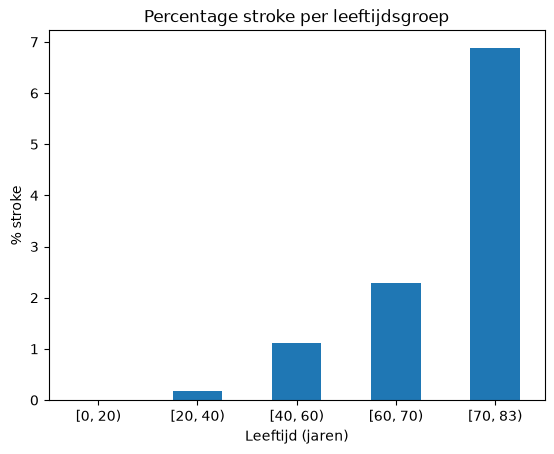

age
[0, 20)     0.01
[20, 40)    0.18
[40, 60)    1.12
[60, 70)    2.28
[70, 83)    6.88
Name: stroke, dtype: float64

In [12]:
age_groups = pd.cut(data.train["age"], bins=[0, 20, 40, 60, 70, 83],
                    right=False)
stroke_by_age = data.train.groupby(age_groups, observed=True)[TARGET].mean()
stroke_by_age = (stroke_by_age * 100).round(2)

stroke_by_age.plot(kind="bar")
plt.title("Percentage stroke per leeftijdsgroep")
plt.xlabel("Leeftijd (jaren)")
plt.ylabel("% stroke")
plt.xticks(rotation=0)
plt.show()
stroke_by_age

In [13]:
smoking_cols = ["smoking_status_formerly smoked",
                "smoking_status_never smoked",
                "smoking_status_smokes"]
# Unknown = alle drie de rookkolommen False
unknown = data.train[smoking_cols].sum(axis=1) == 0
children = data.train["work_type_children"]

print(f"Gemiddelde leeftijd Unknown: "
      f"{data.train.loc[unknown, 'age'].mean():.1f} jaar")
print(f"Kinderen met Unknown: {(unknown & children).sum()} "
      f"van de {children.sum()} kinderen")

Gemiddelde leeftijd Unknown: 28.8 jaar
Kinderen met Unknown: 4343 van de 4848 kinderen


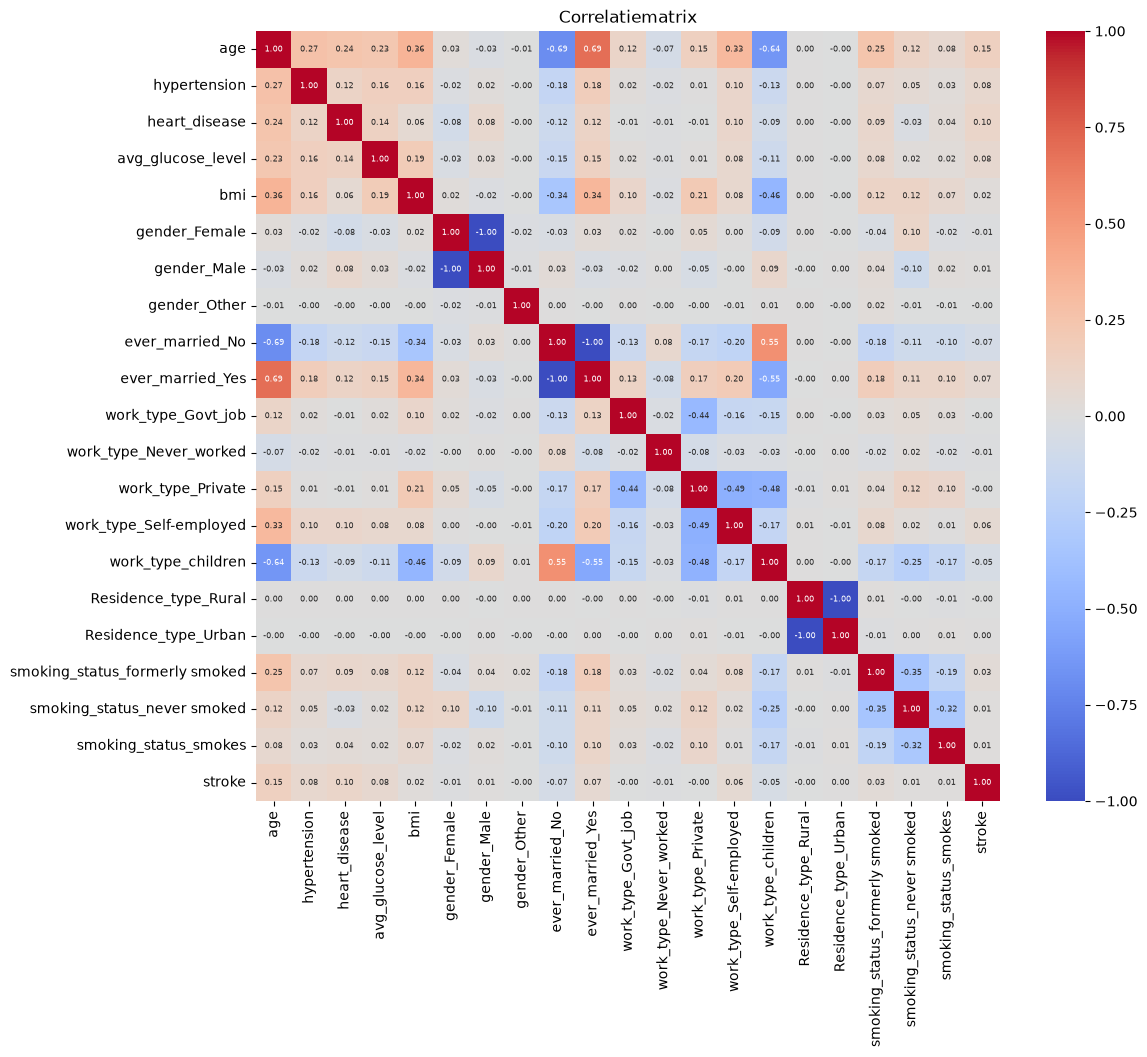

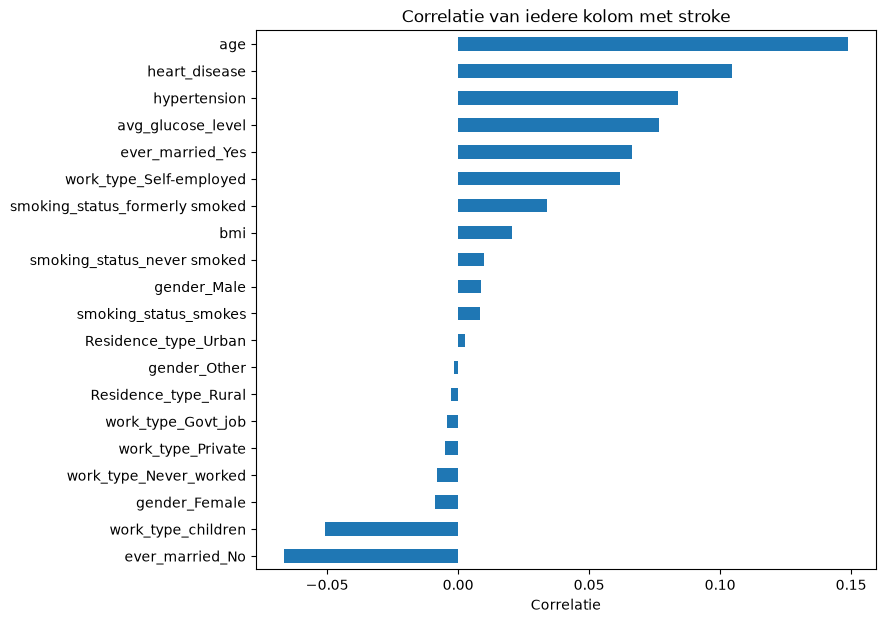

In [14]:
corr = data.train.drop(columns="id").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6})
plt.title("Correlatiematrix")
plt.show()

# Alleen de correlatie met stroke, gesorteerd
target_corr = corr[TARGET].drop(TARGET).sort_values()
target_corr.plot(kind="barh", figsize=(8, 7))
plt.title("Correlatie van iedere kolom met stroke")
plt.xlabel("Correlatie")
plt.show()

### 2.6 Belangrijkste bevindingen

1. **De data is sterk imbalanced.** Maar 1,54% van de patiënten heeft een stroke gehad (517 van de 33.550). Een model dat altijd "geen stroke" voorspelt, heeft al 98,46% accuracy maar vindt geen enkele patiënt met risico. Daarom gebruiken we de F1-score (hoofdstuk 3) en technieken voor imbalanced data (hoofdstuk 4).

2. **Leeftijd is de belangrijkste risicofactor.** Patiënten met een stroke zijn veel ouder: de mediaan is 72 jaar tegenover 43 jaar zonder stroke. Het percentage stroke stijgt van 0,01% onder de 20 jaar naar 6,88% bij 70 jaar en ouder. Leeftijd heeft ook de hoogste correlatie met stroke (0,15).

3. **Hartziekte, hoge bloeddruk en glucose verhogen het risico.** Bij een hartziekte heeft 7,62% een stroke, bij hoge bloeddruk 4,87%. Dat is drie tot vijf keer zo vaak als gemiddeld. Patiënten met stroke hebben ook een hoger glucosegehalte (mediaan 104 tegenover 91). Dit past bij de literatuur, waarin hoge bloeddruk en diabetes belangrijke risicofactoren zijn (O'Donnell et al., 2016).

4. **Sommige verbanden komen eigenlijk door leeftijd.** Getrouwde patiënten (2,16%) en zelfstandigen (3,34%) hebben vaker een stroke, terwijl kinderen bijna nooit een stroke hebben (0,02%). Dit komt waarschijnlijk doordat getrouwde mensen en zelfstandigen gemiddeld ouder zijn, niet door het trouwen of het werk zelf.

5. **De rookstatus "Unknown" hangt samen met kinderen.** 10.320 patiënten (31%) hebben geen bekende rookstatus. Hun gemiddelde leeftijd is 28,8 jaar, en 4.343 van de 4.848 kinderen vallen in deze groep. Vroeger gerookt geeft het hoogste stroke-percentage (2,47%), maar ook die groep is gemiddeld ouder.

6. **Geslacht en woonomgeving maken weinig uit.** Mannen (1,67%) en vrouwen (1,45%), stad (1,57%) en platteland (1,51%) liggen allemaal dicht bij het gemiddelde.

7. **De outliers zijn echt en bevatten informatie.** `avg_glucose_level` heeft 3.641 hoge uitschieters, en daarvan heeft 4,48% een stroke, bijna drie keer zo vaak als gemiddeld. Dit zijn geen fouten maar patiënten met een hoog suikergehalte (mogelijk diabetes). Daarom verwijderen we ze niet. `bmi` heeft 769 outliers met een stroke-percentage van 1,30%, ongeveer gemiddeld.

8. **Er zijn een paar hele kleine groepen.** `gender_Other` komt 6 keer voor en `work_type_Never_worked` 141 keer. Een model kan van zo weinig voorbeelden niets betrouwbaars leren.

9. **Alle correlaties met stroke zijn laag (maximaal 0,15).** Dat is normaal bij een doelvariabele die zo scheef verdeeld is. Bovendien meet correlatie alleen lineaire verbanden. Modellen zoals een decision tree kunnen ook andere patronen vinden.

10. **De numerieke kolommen hebben verschillende schalen** (`age` tot 82, `avg_glucose_level` tot 282). Voor modellen die met afstanden of regularisatie werken (KNN, SVM, logistische regressie) moeten we standaardiseren (2.8).

### 2.7 Data opschonen

In [15]:
class StrokeCleaner:
    """Schoont de stroke-data op en houdt bij welke stappen zijn gedaan."""

    def __init__(self, df):
        # Kopie, zodat de originele data onveranderd blijft
        self.df = df.copy()
        self.log = []

    def drop_rows(self, mask, reason):
        """Verwijdert de rijen waar mask True is."""
        self.log.append({"stap": reason, "rijen weg": mask.sum(),
                         "kolommen weg": 0})
        self.df = self.df[~mask]
        return self

    def drop_columns(self, columns, reason):
        """Verwijdert de opgegeven kolommen."""
        self.log.append({"stap": reason, "rijen weg": 0,
                         "kolommen weg": len(columns)})
        self.df = self.df.drop(columns=columns)
        return self

    def bool_to_int(self):
        """Zet True/False-kolommen om naar 1/0."""
        bool_cols = self.df.select_dtypes(include="bool").columns
        self.df[bool_cols] = self.df[bool_cols].astype(int)
        return self

    def summary(self):
        """Overzicht van alle opschoonstappen."""
        return pd.DataFrame(self.log)

In [16]:
cleaner = StrokeCleaner(data.train)
cleaner.drop_rows(cleaner.df["gender_Other"],
                  "Geslacht 'Other' (te kleine groep)")
cleaner.drop_rows(cleaner.df["bmi"] > 70,
                  "BMI boven 70 (onrealistisch)")
cleaner.drop_columns(["id"], "id (geen medische informatie)")
cleaner.drop_columns(["gender_Other", "gender_Female",
                      "ever_married_No", "Residence_type_Rural"],
                     "Overbodige dummy-kolommen")
cleaner.bool_to_int()

train_clean = cleaner.df
print(f"Voor: {data.train.shape}, na: {train_clean.shape}")
cleaner.summary()

Voor: (33550, 22), na: (33531, 17)


,stap,rijen weg,kolommen weg
0,Geslacht 'Other' (te kleine groep),6,0
1,BMI boven 70 (onrealistisch),13,0
2,id (geen medische informatie),0,1
3,Overbodige dummy-kolommen,0,4


**Waarom deze keuzes**

1. **6 rijen met `gender_Other` verwijderd.** Een model kan van 6 voorbeelden niets betrouwbaars leren. Bovendien had geen van deze 6 patiënten een stroke.
2. **13 rijen met een BMI boven 70 verwijderd.** Er zit bijvoorbeeld een kind van 6 jaar in met een BMI van 96,1. Dat is medisch vrijwel onmogelijk en waarschijnlijk een invoerfout. Ook in deze groep had niemand een stroke, dus we verliezen geen informatie over de kleine groep patiënten die er wel een had. De grens van 70 is onze eigen keuze.
3. **`id` verwijderd.** Dit is alleen een volgnummer en zegt niets over de gezondheid van een patiënt.
4. **4 overbodige dummy-kolommen verwijderd.** Bij een variabele met twee categorieën zegt de ene kolom precies het omgekeerde van de andere. Als `ever_married_Yes` 1 is, is `ever_married_No` altijd 0. De tweede kolom voegt dus niets toe en kan bij logistische regressie zelfs problemen geven (multicollineariteit). Hetzelfde geldt voor stad/platteland en voor man/vrouw, nu "Other" weg is. `gender_Other` is daarna altijd 0, dus die kan ook weg.
5. **True/False omgezet naar 1/0.** Zo hebben alle kolommen dezelfde vorm. Scikit-learn kan ook met True/False werken, maar 0/1 is overzichtelijker.

**Wat we bewust niet verwijderen**

* Outliers bij `avg_glucose_level`, omdat mensen met een hoge waarde juist vaker een stroke hebben (zie 2.5).
* Baby's met een leeftijd onder 1, want dit zijn echte waarden.
* De rokers met status "Unknown", omdat "onbekend" zelf ook informatie bevat (het gaat vooral om kinderen).

**Belangrijk voor later**

Bij de Kaggle-inlevering mogen we geen rijen uit `test.csv` halen, want Kaggle wil voor elke patiënt een voorspelling hebben. Daarom gebruiken we voor de testdata alleen `drop_columns` en `bool_to_int`, zodat de kolommen gelijk zijn aan die van train. Dit is ook de reden dat we er een class van hebben gemaakt: we kunnen hem opnieuw gebruiken.

Elke methode eindigt met `return self`, waardoor we de stappen achter elkaar kunnen aanroepen. Met `summary()` zie je in één tabel wat er is weggehaald en waarom, zodat de bewerkingen goed te controleren zijn.

### 2.8 Standaardiseren

**Standaardiseren**

**Wat is het?** Bij standaardiseren zet je elke numerieke kolom om naar dezelfde schaal, zodat het gemiddelde 0 wordt en de standaardafwijking 1. Voor elke waarde reken je een z-score uit (scikit-learn developers, z.d.):

$$z = \frac{x - \mu}{\sigma}$$

Hierbij is $\mu$ het gemiddelde van de kolom en $\sigma$ de standaardafwijking. Een voorbeeld met de getallen uit onze tabel: een patiënt met een glucosewaarde van 200 krijgt $z = (200 - 103{,}59) / 42{,}13 \approx 2{,}29$. Die waarde ligt dus ongeveer 2,3 standaardafwijkingen boven het gemiddelde. Iemand van 30 jaar krijgt $z = (30 - 41{,}82) / 22{,}48 \approx -0{,}53$, dus iets onder het gemiddelde. De vorm van de verdeling blijft hetzelfde, alleen de schaal verandert.

**Wanneer is het gewenst?** Het is vooral nodig als de kolommen een heel andere schaal hebben en het model daar gevoelig voor is:

* **KNN en SVM** werken met afstanden tussen punten. Als je niet standaardiseert, bepaalt `avg_glucose_level` (55 tot 282) bijna alle afstand en doet `age` of een 0/1-kolom nauwelijks mee.
* **Logistische regressie** heeft er ook baat bij, want gradient descent komt sneller bij de beste waarden uit als alle kolommen een vergelijkbare schaal hebben.
* **Decision trees** (en Random Forest, Gradient Boosting en XGBoost) hebben het niet nodig. Een boom kijkt steeds naar één kolom en stelt een vraag als "is `age` groter dan 60?". Of je nu in jaren rekent of in z-scores, dezelfde mensen komen aan beide kanten van de splitsing terecht.

In [17]:
from sklearn.preprocessing import StandardScaler

# X = features, y = doelvariabele
X_train = train_clean.drop(columns=TARGET)
y_train = train_clean[TARGET]

scaler = StandardScaler()
X_scaled = X_train.copy()
# Alleen de numerieke kolommen standaardiseren, 0/1-kolommen blijven gelijk
X_scaled[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])

pd.DataFrame({
    "gemiddelde voor": X_train[NUMERIC_COLS].mean(),
    "std voor": X_train[NUMERIC_COLS].std(),
    "gemiddelde na": X_scaled[NUMERIC_COLS].mean(),
    "std na": X_scaled[NUMERIC_COLS].std(),
}).round(2)

,gemiddelde voor,std voor,gemiddelde na,std na
age,41.82,22.48,-0.0,1.0
avg_glucose_level,103.58,42.11,-0.0,1.0
bmi,28.58,7.71,0.0,1.0


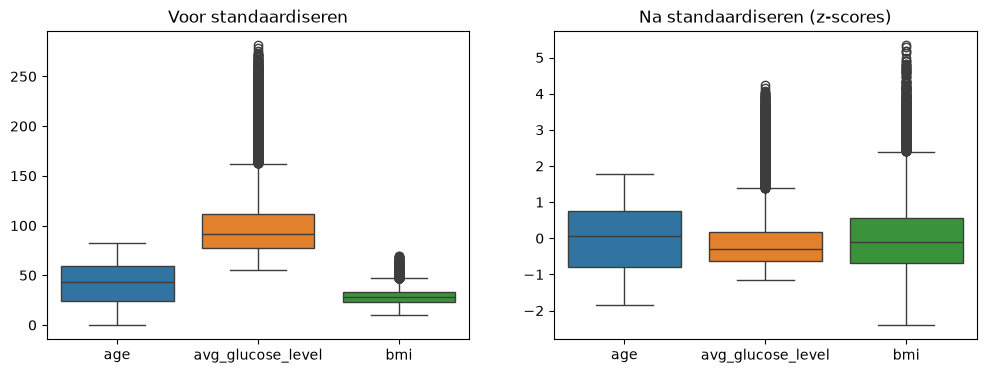

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_train[NUMERIC_COLS], ax=axes[0])
axes[0].set_title("Voor standaardiseren")
sns.boxplot(data=X_scaled[NUMERIC_COLS], ax=axes[1])
axes[1].set_title("Na standaardiseren (z-scores)")
plt.show()

**Resultaat**

Na het standaardiseren is het gemiddelde van elke kolom 0 en de standaardafwijking 1. Soms staat er `-0.0` in de output, maar dat is gewoon 0. Het komt door een heel klein afrondingsverschil van de computer.

**Voegt het hier waarde toe?** Ja. `age`, `avg_glucose_level` en `bmi` hebben allemaal een andere schaal (zie 2.3) en we gaan KNN, SVM en logistische regressie gebruiken. De 0/1-kolommen laten we zoals ze zijn, want die hebben al een kleine schaal die voor alle kolommen gelijk is.

**Belangrijk voor hoofdstuk 4:** `X_scaled` gebruiken we hier alleen om te laten zien wat standaardiseren doet. Bij het trainen met cross-validatie stoppen we de scaler in een `Pipeline`. Zo berekent die het gemiddelde en de standaardafwijking alleen op het trainingsdeel van elke fold. Als we dat niet doen, komt er informatie uit het validatiedeel in het model terecht (data leakage), waardoor de score beter lijkt dan hij echt is.

## 3. Evaluatie

### 3.1 Metrics

In [19]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Features en doelvariabele
X = train_clean.drop(columns="stroke")
y = train_clean["stroke"]

# Verdeel de data in 80% training en 20% validatie
X_train_eval, X_val, y_train_eval, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standaardiseer alleen de numerieke kolommen
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), NUMERIC_COLS)
    ],
    remainder="passthrough"
)

# Maak een pipeline met standaardisatie en Logistic Regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train het model
model.fit(X_train_eval, y_train_eval)

# Voorspel de validatiedata
y_pred = model.predict(X_val)

# Bereken de evaluatiemetrics
print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(
    y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred), 4))
print("F1-score:", round(f1_score(y_val, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))


Accuracy: 0.9846
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      6604
           1       0.00      0.00      0.00       103

    accuracy                           0.98      6707
   macro avg       0.49      0.50      0.50      6707
weighted avg       0.97      0.98      0.98      6707






Bij classificatie voorspelt een machinelearningmodel tot welke klasse een patiënt behoort. In onze dataset betekent `stroke = 0` dat een patiënt geen herseninfarct heeft gehad en `stroke = 1` dat een patiënt wel een herseninfarct heeft gehad.

Om te bepalen hoe goed ons model presteert, gebruiken we verschillende evaluatiemetrics.

**Accuracy**

Accuracy geeft aan welk percentage van alle voorspellingen correct is. Hierbij wordt gekeken naar zowel de correct voorspelde patiënten zonder stroke als de correct voorspelde patiënten met stroke.

**Precision**

Precision geeft aan hoeveel patiënten daadwerkelijk een stroke hebben gehad van alle patiënten waarbij het model een stroke voorspelt.

**Recall**

Recall geeft aan hoeveel patiënten met een stroke correct worden herkend door het model.

**F1-score**

De F1-score is het harmonisch gemiddelde van precision en recall. Deze metric houdt rekening met zowel False Positives als False Negatives.

Voor onze evaluatie gebruiken we Logistic Regression als basismodel. Dit model is relatief eenvoudig en goed uitlegbaar.

We verdelen de dataset in 80% trainingsdata en 20% validatiedata. Hierbij gebruiken we `stratify=y`, zodat de verhouding tussen patiënten met en zonder stroke ongeveer gelijk blijft.

Om data leakage te voorkomen, wordt de standaardisatie uitsluitend op de trainingsdata getraind.



### 3.2 Confusion matrix

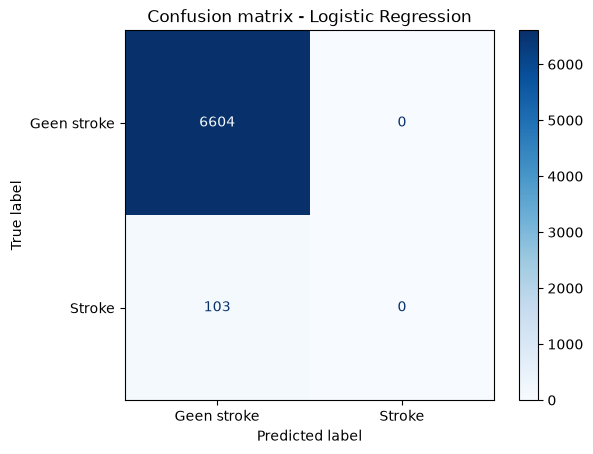

True Negatives: 6604
False Positives: 0
False Negatives: 103
True Positives: 0

Handmatig berekende metrics:
Accuracy: 0.9846
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000


In [20]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Bereken de confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

# Visualiseer de confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Geen stroke", "Stroke"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix - Logistic Regression")
plt.show()

# Haal de vier onderdelen uit de matrix
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Bereken de metrics met de formules
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print("\nHandmatig berekende metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")






Een confusion matrix laat zien hoeveel voorspellingen van een classificatiemodel correct en incorrect zijn.

De confusion matrix bestaat uit vier onderdelen:

- **True Positive (TP):** Het model voorspelt een stroke en de patiënt heeft daadwerkelijk een stroke gehad.
- **True Negative (TN):** Het model voorspelt geen stroke en de patiënt heeft daadwerkelijk geen stroke gehad.
- **False Positive (FP):** Het model voorspelt een stroke, maar de patiënt heeft geen stroke gehad.
- **False Negative (FN):** Het model voorspelt geen stroke, maar de patiënt heeft wel een stroke gehad.

Voor onze medische toepassing zijn False Negatives extra belangrijk. Dit zijn patiënten die een stroke hebben gehad, maar die niet door het model worden herkend.

Met de waarden uit de confusion matrix kunnen we verschillende evaluatiemetrics berekenen.

**Accuracy**

Accuracy is het aantal correcte voorspellingen gedeeld door het totale aantal voorspellingen.

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Precision**

Precision is het aantal True Positives gedeeld door alle positief voorspelde patiënten.

$$
Precision = \frac{TP}{TP + FP}
$$

**Recall**

Recall is het aantal True Positives gedeeld door alle patiënten die daadwerkelijk een stroke hebben gehad.

$$
Recall = \frac{TP}{TP + FN}
$$

**F1-score**

De F1-score combineert precision en recall tot één score.

$$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

Een hoge F1-score betekent dat het model een goede balans heeft tussen precision en recall.

Bij de evaluatie gebruiken we de confusion matrix om te onderzoeken welke fouten het model maakt en welke gevolgen deze fouten kunnen hebben.


### 3.3 Waarom F1-score?




Voor deze opdracht gebruiken we de F1-score als belangrijkste evaluatiemetric. Dit komt doordat onze dataset sterk imbalanced is.

Uit onze Exploratieve Data Analyse (EDA) blijkt dat slechts 1,54% van de patiënten een stroke heeft gehad. De overige 98,46% heeft geen stroke gehad.

Dit betekent dat de twee klassen niet gelijk verdeeld zijn.

Wanneer een model bij iedere patiënt voorspelt dat deze geen stroke heeft gehad, behaalt het al een accuracy van ongeveer 98,46%. Toch herkent dit model geen enkele patiënt die daadwerkelijk een stroke heeft gehad.

Hierdoor kan accuracy een misleidend beeld geven van de prestaties van het model.

De F1-score is in deze situatie een geschiktere evaluatiemetric, omdat deze rekening houdt met zowel precision als recall.

- **Precision:** Hoeveel van de voorspelde strokegevallen zijn daadwerkelijk strokegevallen?
- **Recall:** Hoeveel van de daadwerkelijke strokegevallen worden correct herkend?

Voor onze medische toepassing is recall extra belangrijk. Een False Negative betekent namelijk dat een patiënt met een stroke niet wordt herkend door het model.

Tegelijkertijd is precision belangrijk, omdat te veel False Positives kunnen leiden tot onnodige vervolgonderzoeken.

De F1-score combineert deze twee metrics en zorgt ervoor dat een model niet alleen goed scoort door de grootste klasse te voorspellen.

Daarom gebruiken we de F1-score om de verschillende machinelearningmodellen in deze Kaggle-competitie met elkaar te vergelijken.

Hoewel de F1-score geschikt is voor deze competitie, is het voor een medische toepassing ook belangrijk om afzonderlijk naar recall en precision te kijken.


## 4. Modellen

### 4.1 Imbalanced data

### 4.2 K-Nearest Neighbors

#### Uitleg
#### Resultaten

### 4.3 Logistic Regression

#### Uitleg
#### Resultaten

### 4.4 Support Vector Machine

#### Uitleg
#### Resultaten

### 4.5 Decision Tree

#### Uitleg
#### Resultaten

### 4.6 Random Forest

#### Uitleg
#### Resultaten

### 4.7 Gradient Boosting

#### Uitleg
#### Resultaten

### 4.8 XGBoost

#### Uitleg
#### Resultaten

### 4.9 Eigen ensemble

#### Uitleg
#### Resultaten

## 5. Conclusie en advies

### 5.1 Overzicht scores

| Model | F1 notebook | F1 Kaggle |
|---|---|---|
| KNN | | |
| Logistic Regression | | |
| SVM | | |
| Decision Tree | | |
| Random Forest | | |
| Gradient Boosting | | |
| XGBoost | | |
| Eigen ensemble | | |

### 5.2 Welk model presteert het beste?

### 5.3 Andere overwegingen

### 5.4 Advies aan artsen

## 6. Referenties

O'Donnell, M. J., Chin, S. L., Rangarajan, S., Xavier, D., Liu, L., Zhang, H., ... Yusuf, S. (2016). Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): A case-control study. *The Lancet, 388*(10046), 761–775. https://doi.org/10.1016/S0140-6736(16)30506-2

scikit-learn developers. (z.d.). *StandardScaler*. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
